<font size = 1 color="gray">Máster Universitario en inteligencia artificial (MUIA)</font>  


## Momentum

En este notebook comparamos tres formas de actualizar un parámetro con el gradiente:

1. **Descenso de gradiente con tasa de aprendizaje constante**, el algoritmo básico que vimos en la sesión 2.
2. **Momentum**, que añade una "velocidad" acumulada para ganar inercia.
3. **Gradiente acelerado de Nesterov (NAG)**, que corrige esa inercia evaluando el gradiente en una posición futura.

Para poder visualizarlo todo, trabajamos con una función de **una sola variable** con varios mínimos locales. En una red neuronal el parámetro sería el vector de todos los pesos y la función sería la pérdida, pero la dinámica es la misma.

### Recordatorio: descenso de gradiente

La derivada $f'(x)$ indica la pendiente de la función en el punto $x$. Si es positiva, la función crece hacia la derecha, así que para bajar hay que moverse hacia la izquierda, y al revés. Por eso la actualización resta el gradiente:

$$x_{t+1} = x_t - \eta\, f'(x_t)$$

* $\eta$ es la **tasa de aprendizaje**: controla el tamaño del paso.
* El paso es proporcional a la pendiente: grande donde la función es empinada y pequeño cerca de un punto plano.
* El algoritmo **no tiene memoria**: cada paso solo depende del gradiente en el punto actual.

Esta última característica es la que provoca el problema que vamos a estudiar: en cuanto el algoritmo cae en un valle, aunque sea poco profundo, la pendiente se anula y se queda allí. **Converge al mínimo local más cercano al punto de partida**, no necesariamente al mínimo absoluto.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### La función objetivo

Buscamos el mínimo en el intervalo $[0, 2]$ de

$$f(x) = 4 - 0.3x - x^2 + 0.55x^3 - 0.2\,\sin(8x)$$

cuya derivada, implementada en `mygrad`, es

$$f'(x) = -0.3 - 2x + 1.65x^2 - 1.6\cos(8x)$$

El polinomio cúbico da la forma general de la curva; el término $-0.2\sin(8x)$ añade una **ondulación** que crea varios valles. En el intervalo hay tres mínimos:

| Mínimo | $x$ | $f(x)$ | Tipo |
|---|---|---|---|
| Izquierdo | ≈ 0.253 | ≈ 3.689 | local |
| Central | ≈ 1.031 | ≈ 3.046 | **absoluto** |
| Derecho | ≈ 1.682 | ≈ 3.128 | local |

Es una versión de juguete del **paisaje de pérdida** de una red neuronal, que en miles de dimensiones está lleno de mínimos locales, mesetas y puntos de silla.

En la celda también se definen los elementos comunes a los tres métodos:

* **Criterio de parada** (`convergido`). Se exige a la vez que el desplazamiento sea muy pequeño, $|x_{t+1}-x_t| < 10^{-7}$, y que el gradiente sea casi nulo, $|f'(x)| < 10^{-5}$. La primera condición sola no basta con momentum: en los puntos de retorno de una oscilación la velocidad pasa por cero y el algoritmo podría detenerse en un punto que no es un mínimo.
* **Detección de divergencia** (`divergido`). Si la trayectoria sale claramente del intervalo de trabajo o el valor deja de ser finito, se interrumpe el bucle. Fuera de $[0, 2]$ domina el término cúbico y la pendiente crece sin límite.
* **`MAXPASOS`** limita el número de iteraciones por si el algoritmo no converge.
* **`dibujar`** muestra la trayectoria: los puntos azules son las posiciones intermedias y el rojo, la posición final.

*Nota:* `npunt` solo determina la resolución con la que se dibuja la curva; no afecta al algoritmo de optimización.

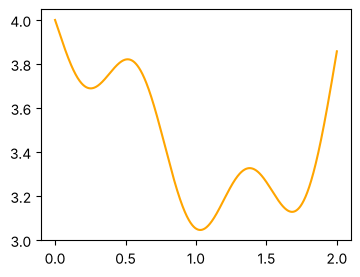

In [2]:
# Encontrar el mínimo de la función 4 - 0.3*x - x**2 + 0.55*x**3 - 0.2*np.sin(8*x) entre x=0 y x=2
liminf = 0
limsup = 2
MAXPASOS = 1000
EPSILON = 1e-7         # umbral para el desplazamiento |x(t+1) - x(t)|
EPSILON_GRAD = 1e-5    # umbral para el gradiente |f'(x)|
npunt = 1000           # puntos usados para dibujar la curva
myx = np.linspace(liminf, limsup, npunt)

def myfunc(x):
    return 4 - 0.3*x - x**2 + 0.55*x**3 - 0.2*np.sin(8*x)

def mygrad(x):
    return -0.3 - 2*x + 1.65*x**2 - 1.6*np.cos(8*x)

def convergido(xpos, xnew):
    """Se detiene solo si el paso es diminuto Y el gradiente es casi nulo."""
    return abs(xnew - xpos) < EPSILON and abs(mygrad(xnew)) < EPSILON_GRAD

def divergido(x):
    """La trayectoria ha salido del intervalo de trabajo o ya no es un número finito."""
    return (not np.isfinite(x)) or x < liminf - 0.5 or x > limsup + 0.5

def dibujar(xdescent, titulo):
    xd = np.array(xdescent)
    dentro = (xd >= liminf) & (xd <= limsup)   # solo se dibujan los puntos del intervalo
    plt.figure(figsize=(4, 3))
    plt.plot(myx, y, color="orange")
    plt.plot(xd[dentro], myfunc(xd[dentro]), 'bo', markersize=2)
    if dentro[-1]:
        plt.plot(xd[-1], myfunc(xd[-1]), 'ro', markersize=4)
    plt.title(titulo, fontsize=8)
    plt.show()

def informe(xdescent, estado):
    print(f'{estado} tras {len(xdescent) - 1} pasos. x final = {xdescent[-1]:.4f}, f(x) = {myfunc(xdescent[-1]):.4f}')

y = myfunc(myx)
plt.figure(figsize=(4, 3))
plt.plot(myx, y, color="orange")
plt.show()

### Descenso de gradiente con $\eta$ constante

La celda siguiente aplica la regla $x_{t+1} = x_t - \eta f'(x_t)$ hasta que converge, diverge o alcanza `MAXPASOS`. La lista `xdescent` guarda la trayectoria.

Prueba los dos puntos de partida cambiando el valor de `xini`:

* Desde $x_0 = 0.05$, el algoritmo baja por la pendiente y se detiene en el **mínimo local izquierdo** ($x \approx 0.253$) en unos 57 pasos.
* Desde $x_0 = 1.90$, se detiene en el **mínimo local derecho** ($x \approx 1.682$) en unos 43 pasos.

En ninguno de los dos casos alcanza el mínimo absoluto. Aumentar $\eta$ no es una solución general: un paso demasiado grande hace que el algoritmo oscile o diverja.

Convergencia tras 57 pasos. x final = 0.2530, f(x) = 3.6892


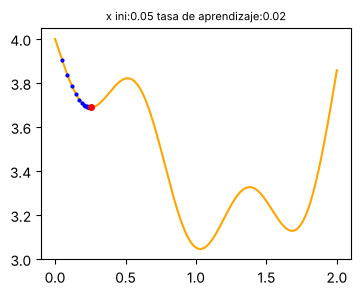

In [3]:
xini = 0.05      # prueba también con 1.90
eta = 0.02

xpos = xini
xdescent = [xini]
estado = f'Sin converger (MAXPASOS = {MAXPASOS})'
for paso in range(MAXPASOS):
    xnew = xpos - eta*mygrad(xpos)
    xdescent.append(xnew)
    if divergido(xnew):
        estado = 'Divergencia'
        break
    if convergido(xpos, xnew):
        estado = 'Convergencia'
        break
    xpos = xnew

titulo = f'x ini:{xini} tasa de aprendizaje:{eta}'
informe(xdescent, estado)
dibujar(xdescent, titulo)

### Momentum

Imaginemos una pelota pesada que rueda por la ladera. Al bajar gana velocidad y, si encuentra una vaguada poco profunda, la supera gracias a la **inercia**. *Momentum* imita ese comportamiento introduciendo una variable de **velocidad** $v$:

$$v_{t+1} = \beta\, v_t - \eta\, f'(x_t)$$
$$x_{t+1} = x_t + v_{t+1}$$

* $\beta \in [0, 1)$ es el coeficiente de momento (en la práctica, entre 0.90 y 0.99). Actúa como un "rozamiento": determina qué fracción de la velocidad anterior se conserva.
* Con $\beta = 0$ se recupera exactamente el descenso de gradiente convencional.

Si desarrollamos la recursión, la velocidad es una **media móvil ponderada exponencialmente** de todos los gradientes anteriores:

$$v_{t+1} = -\eta \sum_{k=0}^{t} \beta^{k} f'(x_{t-k})$$

Los gradientes recientes pesan más, pero los antiguos no se olvidan. Si la pendiente mantiene el signo durante varios pasos, los términos se suman y el paso efectivo puede llegar a ser hasta $\eta/(1-\beta)$ veces el gradiente. Con los valores de la celda ($\eta = 0.02$, $\beta = 0.95$), eso es **20 veces** el paso del descenso de gradiente simple. En cambio, si el gradiente cambia de signo, los términos se cancelan y las oscilaciones se amortiguan.

En el código, `vpos` es $v_t$ y `vnew` es $v_{t+1}$.

Convergencia tras 527 pasos. x final = 1.0305, f(x) = 3.0458


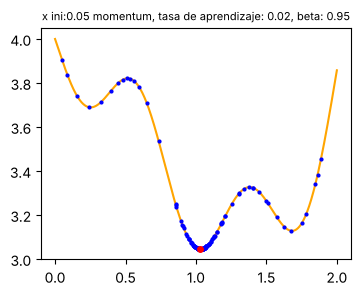

In [4]:
xini = 0.05      # prueba también con 1.90
eta = 0.02
beta = 0.95

xpos = xini
vpos = 0
xdescent = [xini]
estado = f'Sin converger (MAXPASOS = {MAXPASOS})'
for paso in range(MAXPASOS):
    vnew = beta*vpos - eta*mygrad(xpos)
    xnew = xpos + vnew
    xdescent.append(xnew)
    if divergido(xnew):
        estado = 'Divergencia'
        break
    if convergido(xpos, xnew):
        estado = 'Convergencia'
        break
    xpos = xnew
    vpos = vnew

titulo = f'x ini:{xini} momentum, tasa de aprendizaje: {eta}, beta: {beta}'
informe(xdescent, estado)
dibujar(xdescent, titulo)

**Interpretación.** Desde $x_0 = 0.05$, la inercia acumulada en la bajada permite superar el primer valle y el algoritmo termina en el **mínimo absoluto** ($x \approx 1.03$). Desde $x_0 = 1.90$ también lo alcanza.

Observa la trayectoria:

* **Oscilaciones (*overshooting*):** la pelota pasa de largo del mínimo y vuelve varias veces antes de detenerse. Con un $\beta$ muy alto, la velocidad puede llegar a sacarla también del mínimo bueno.
* **Número de pasos:** necesita unos 500 pasos, frente a los 57 del descenso de gradiente. Llega a un mínimo mejor, pero tarda más en asentarse porque la inercia lo hace oscilar alrededor del fondo del valle.

### Gradiente acelerado de Nesterov (NAG)

Momentum calcula el gradiente en la posición actual y después suma la velocidad acumulada: "primero calcula, luego salta". **NAG** invierte el orden: primero da un salto provisional en la dirección de la inercia y calcula el gradiente en ese **punto anticipado**:

$$v_{t+1} = \beta\, v_t - \eta\, f'(x_t + \beta v_t)$$
$$x_{t+1} = x_t + v_{t+1}$$

La única diferencia con momentum está en el argumento del gradiente: `mygrad(xpos + beta*vpos)` en lugar de `mygrad(xpos)`.

**Intuición:** si la inercia está a punto de llevarnos más allá del fondo del valle, el gradiente en el punto anticipado ya apunta en sentido contrario y genera una fuerza de frenado *antes* de pasarse. NAG funciona como un **freno adaptativo**: reduce las oscilaciones en las zonas de mucha curvatura.

Para que la comparación con momentum sea justa, la celda usa **los mismos hiperparámetros** ($\eta = 0.02$, $\beta = 0.95$).

Convergencia tras 94 pasos. x final = 0.2530, f(x) = 3.6892


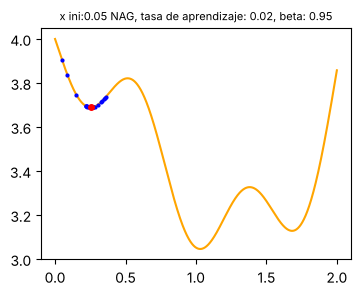

In [5]:
xini = 0.05      # prueba también con 1.90
eta = 0.02
beta = 0.95

xpos = xini
vpos = 0
xdescent = [xini]
estado = f'Sin converger (MAXPASOS = {MAXPASOS})'
for paso in range(MAXPASOS):
    vnew = beta*vpos - eta*mygrad(xpos + beta*vpos)   # gradiente en el punto anticipado
    xnew = xpos + vnew
    xdescent.append(xnew)
    if divergido(xnew):
        estado = 'Divergencia'
        break
    if convergido(xpos, xnew):
        estado = 'Convergencia'
        break
    xpos = xnew
    vpos = vnew

titulo = f'x ini:{xini} NAG, tasa de aprendizaje: {eta}, beta: {beta}'
informe(xdescent, estado)
dibujar(xdescent, titulo)

**Interpretación.** Con los mismos hiperparámetros que momentum, NAG converge mucho antes (menos de 100 pasos) y con muchas menos oscilaciones, pero **se queda en el mínimo local** desde los dos puntos de partida. El mismo freno que elimina las oscilaciones le quita la inercia que necesitaba para salir del primer valle. En un paisaje con muchos mínimos locales, frenar antes no siempre es una ventaja.

NAG es además **muy sensible a la tasa de aprendizaje**. La celda siguiente lo ejecuta con varios valores de $\eta$ desde los dos puntos de partida:

* Con $\eta$ pequeño se queda en el mínimo local más cercano.
* Con $\eta = 0.10$, desde $x_0 = 1.90$ sí alcanza el mínimo absoluto.
* Con $\eta = 0.12$ el paso es demasiado grande para la curvatura del fondo del valle: desde $x_0 = 0.05$ el algoritmo queda **saltando alrededor del mínimo sin converger**, y desde $x_0 = 1.90$ el primer salto lo saca del intervalo y **diverge**.

In [6]:
def nag(xini, eta, beta):
    """Versión compacta del bucle anterior. Devuelve la trayectoria y el estado final."""
    xpos, vpos, xdescent = xini, 0, [xini]
    for paso in range(MAXPASOS):
        vnew = beta*vpos - eta*mygrad(xpos + beta*vpos)
        xnew = xpos + vnew
        xdescent.append(xnew)
        if divergido(xnew):
            return xdescent, 'Divergencia'
        if convergido(xpos, xnew):
            return xdescent, 'Convergencia'
        xpos, vpos = xnew, vnew
    return xdescent, 'Sin converger'

beta = 0.90
print(f'NAG con beta = {beta}')
print(f"{'x ini':>6} {'eta':>6}  {'estado':<14} {'pasos':>6} {'x final':>9}")
for xini in (0.05, 1.90):
    for eta in (0.02, 0.05, 0.10, 0.12):
        tray, estado = nag(xini, eta, beta)
        xfin = f'{tray[-1]:9.4f}' if estado != 'Divergencia' else '        -'
        print(f'{xini:6.2f} {eta:6.2f}  {estado:<14} {len(tray) - 1:6d} {xfin}')

NAG con beta = 0.9
 x ini    eta  estado          pasos   x final
  0.05   0.02  Convergencia       75    0.2530
  0.05   0.05  Convergencia       32    0.2530
  0.05   0.10  Convergencia       13    0.2530
  0.05   0.12  Sin converger    1000    1.0166
  1.90   0.02  Convergencia       64    1.6823
  1.90   0.05  Convergencia       26    1.6823
  1.90   0.10  Convergencia      171    1.0305
  1.90   0.12  Divergencia         8         -


### Comparación de los tres métodos

La última celda ejecuta los tres métodos con los mismos hiperparámetros desde los dos puntos de partida y dibuja, para cada uno, la evolución de $f(x_t)$ con el número de paso. Así se ven a la vez la velocidad de convergencia y el mínimo que alcanza cada método:

* El descenso de gradiente y NAG bajan rápido, pero se estabilizan en un valor alto de $f$: el de un mínimo local.
* Momentum tarda más y oscila, pero termina en el valor más bajo: el del mínimo absoluto, $f \approx 3.046$ (línea discontinua).

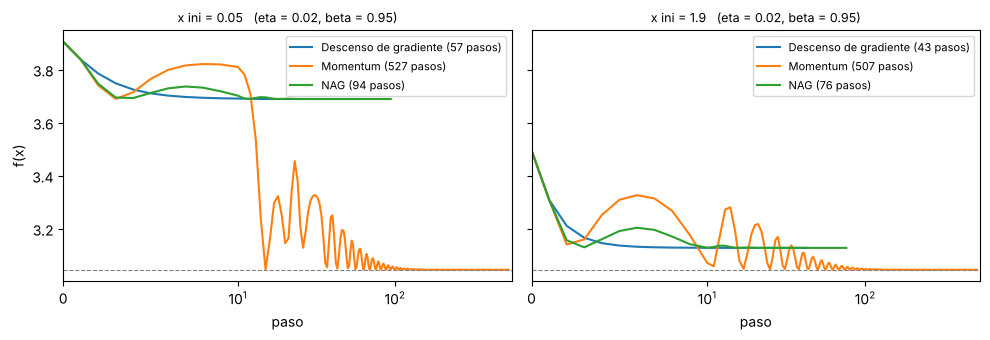

In [7]:
def trayectoria(xini, eta, beta=0.0, nesterov=False):
    """Descenso de gradiente (beta = 0), momentum o NAG con el mismo bucle."""
    xpos, vpos, xdescent = xini, 0, [xini]
    for paso in range(MAXPASOS):
        g = mygrad(xpos + beta*vpos) if nesterov else mygrad(xpos)
        vnew = beta*vpos - eta*g
        xnew = xpos + vnew
        xdescent.append(xnew)
        if divergido(xnew) or convergido(xpos, xnew):
            break
        xpos, vpos = xnew, vnew
    return np.array(xdescent)

eta, beta = 0.02, 0.95
metodos = [('Descenso de gradiente', dict(beta=0.0)),
           ('Momentum', dict(beta=beta)),
           ('NAG', dict(beta=beta, nesterov=True))]
fmin = myfunc(myx).min()

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for eje, xini in zip(ejes, (0.05, 1.90)):
    for nombre, params in metodos:
        tray = trayectoria(xini, eta, **params)
        eje.plot(myfunc(tray), label=f'{nombre} ({len(tray) - 1} pasos)')
    eje.axhline(fmin, color='gray', linestyle='--', linewidth=0.8)
    eje.set_xscale('symlog', linthresh=10)
    eje.set_xlim(left=0)
    eje.set_title(f'x ini = {xini}   (eta = {eta}, beta = {beta})', fontsize=9)
    eje.set_xlabel('paso')
    eje.legend(fontsize=8)
ejes[0].set_ylabel('f(x)')
plt.tight_layout()
plt.show()

### Resumen

| Método | Actualización | Ventaja | Limitación |
|---|---|---|---|
| Descenso de gradiente | $x_{t+1} = x_t - \eta f'(x_t)$ | Simple y estable con $\eta$ pequeño | Queda atrapado en el mínimo local más cercano |
| Momentum | $v_{t+1} = \beta v_t - \eta f'(x_t)$ | La inercia permite superar valles poco profundos y acelera en pendientes constantes | Oscilaciones y *overshooting* con $\beta$ alto |
| NAG | $v_{t+1} = \beta v_t - \eta f'(x_t + \beta v_t)$ | Frena antes de pasarse del mínimo: menos oscilaciones | Ese freno puede impedir escapar de mínimos locales; muy sensible a $\eta$ |

Ninguno de estos métodos adapta la tasa de aprendizaje a cada parámetro. Esa es la idea de **AdaGrad**, **RMSProp** y **Adam**, que combina momentum con una escala adaptativa y es el optimizador más usado hoy en día.

### Para experimentar

1. Fija $\eta = 0.02$ y prueba $\beta \in \{0.5, 0.8, 0.9, 0.95, 0.99\}$ en momentum. ¿A partir de qué valor escapa del mínimo local? ¿Qué ocurre con $\beta = 0.99$?
2. Busca una combinación de $\eta$ y $\beta$ con la que NAG alcance el mínimo absoluto desde los dos puntos de partida.
3. Quita la condición sobre el gradiente en `convergido` y observa si alguno de los métodos se detiene antes de tiempo.
4. Cambia la amplitud del término $\sin(8x)$ en `myfunc` y `mygrad`. ¿Cómo afecta a la dificultad del problema?

---

<font size="1" color="grey">
    (c) 2026 Javier García Algarra. <a href='https://www.u-tad.com'>www.u-tad.com</a> <br>
Licensed under a Creative Commons Reconocimiento 4.0 Internacional License
</font> 